# UNIT 2 – FLIGHT DELAY PREDICTION USING MATHEMATICAL ML MODELS

**Project:** Flight Delay and Cancellation Prediction System  
**Unit:** 2 – Regression and Classification Models  
**Implementation:** NumPy-based implementations of the algorithms (no ready-made ML model classes).

## Aim
To formulate and implement regression and classification models for estimating flight arrival delay and classifying whether a flight will arrive more than 15 minutes late.

## Algorithms covered
1. Maximum Likelihood Estimation (MLE) and Least Squares Linear Regression
2. Robust Linear Regression (Huber loss using Iteratively Reweighted Least Squares)
3. Ridge Regression (L2 regularisation)
4. Bayesian Linear Regression
5. Linear classification using a discriminant function
6. Probabilistic generative classification (Gaussian class-conditional model)
7. Probabilistic discriminative classification (Logistic Regression)
8. Bayesian Logistic Regression using a Laplace approximation
9. Kernel functions and the kernel trick
10. Support Vector Machine (SVM) with a kernel (simplified Sequential Minimal Optimisation)

> **Important modelling note:** The uploaded Unit 1 notebook used `DEPARTURE_DELAY` as an input. That value is only known after the flight has departed and can make a model look unrealistically strong for a pre-departure prediction task. This Unit 2 notebook deliberately uses scheduled information only: month, day, day of week, scheduled departure hour and distance. It predicts `ARRIVAL_DELAY`; it does not claim to predict cancellations. The target definition is arrival delay greater than 15 minutes.

### Library restriction
The algorithms below are implemented with NumPy. Pandas is used to load and prepare the CSV file, and Matplotlib is used for plots. No scikit-learn model, scaler, train/test split, metric, or SVM implementation is used.

In [21]:
# 1. IMPORTS AND REPRODUCIBILITY
import os, glob, time, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

NumPy: 2.1.3
Pandas: 2.3.3


## 2. Load and prepare the flight dataset\nThe code searches Kaggle input folders for `flights.csv`. Add the same flight-delay dataset used in your Unit 1 notebook if the file is not found.

In [22]:
# 2. LOAD DATA
import os
import glob
import pandas as pd
import numpy as np

# Automatically locate flights.csv
files = glob.glob('/kaggle/input/**/flights.csv', recursive=True)

if not files:
    raise FileNotFoundError("flights.csv not found. Check Add Input.")

FLIGHTS_PATH = files[0]

print("Using:", FLIGHTS_PATH)

required = [
    "MONTH",
    "DAY",
    "DAY_OF_WEEK",
    "SCHEDULED_DEPARTURE",
    "DISTANCE",
    "ARRIVAL_DELAY"
]

df = pd.read_csv(
    FLIGHTS_PATH,
    usecols=required,
    low_memory=False
)

print("Raw shape:", df.shape)

df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna(subset=required).copy()

print("Cleaned shape:", df.shape)
display(df.head())

Using: /kaggle/input/datasets/usdot/flight-delays/flights.csv
Raw shape: (5819079, 6)
Cleaned shape: (5714008, 6)


,MONTH,DAY,DAY_OF_WEEK,SCHEDULED_DEPARTURE,DISTANCE,ARRIVAL_DELAY
0,1,1,4,5,1448,-22.0
1,1,1,4,10,2330,-9.0
2,1,1,4,20,2296,5.0
3,1,1,4,20,2342,-9.0
4,1,1,4,25,1448,-21.0


In [23]:
# 3. FEATURE ENGINEERING AND TARGETS
# Convert HHMM scheduled departure to hour, e.g. 1530 -> 15
scheduled = pd.to_numeric(df["SCHEDULED_DEPARTURE"], errors="coerce").fillna(0).astype(int)
hour = (scheduled // 100).clip(0, 23).to_numpy()
month = df["MONTH"].to_numpy(dtype=float)
day = df["DAY"].to_numpy(dtype=float)
dow = df["DAY_OF_WEEK"].to_numpy(dtype=float)
distance = df["DISTANCE"].to_numpy(dtype=float)

# Cyclic encoding preserves the circular nature of hour, month and weekday
X_all = np.column_stack([
    month, day, dow, distance, hour,
    np.sin(2*np.pi*hour/24), np.cos(2*np.pi*hour/24),
    np.sin(2*np.pi*month/12), np.cos(2*np.pi*month/12),
    np.sin(2*np.pi*dow/7), np.cos(2*np.pi*dow/7)
])
feature_names = ["MONTH", "DAY", "DAY_OF_WEEK", "DISTANCE", "DEP_HOUR",
                 "HOUR_SIN", "HOUR_COS", "MONTH_SIN", "MONTH_COS", "DOW_SIN", "DOW_COS"]
y_reg_all = df["ARRIVAL_DELAY"].to_numpy(dtype=float)
y_cls_all = (y_reg_all > 15).astype(int)
print("Features:", feature_names)
print("Regression target: ARRIVAL_DELAY (minutes)")
print("Classification target: 1 if ARRIVAL_DELAY > 15 minutes, else 0")
print("Class distribution:", pd.Series(y_cls_all).value_counts().sort_index().to_dict())

Features: ['MONTH', 'DAY', 'DAY_OF_WEEK', 'DISTANCE', 'DEP_HOUR', 'HOUR_SIN', 'HOUR_COS', 'MONTH_SIN', 'MONTH_COS', 'DOW_SIN', 'DOW_COS']
Regression target: ARRIVAL_DELAY (minutes)
Classification target: 1 if ARRIVAL_DELAY > 15 minutes, else 0
Class distribution: {0: 4690510, 1: 1023498}


In [24]:
# 4. MANUAL TRAIN / VALIDATION / TEST SPLIT AND STANDARDISATION
n = len(X_all)
indices = np.random.permutation(n)
n_train = int(0.70*n)
n_val = int(0.15*n)
train_idx = indices[:n_train]
val_idx = indices[n_train:n_train+n_val]
test_idx = indices[n_train+n_val:]

X_train_raw, X_val_raw, X_test_raw = X_all[train_idx], X_all[val_idx], X_all[test_idx]
# Fit scaling parameters only on training data to avoid data leakage
mu = X_train_raw.mean(axis=0)
sigma = X_train_raw.std(axis=0)
sigma[sigma == 0] = 1.0
X_train = (X_train_raw-mu)/sigma
X_val = (X_val_raw-mu)/sigma
X_test = (X_test_raw-mu)/sigma
# Add intercept column
Xtr = np.column_stack([np.ones(len(X_train)), X_train])
Xva = np.column_stack([np.ones(len(X_val)), X_val])
Xte = np.column_stack([np.ones(len(X_test)), X_test])
ytr = y_reg_all[train_idx]
yva = y_reg_all[val_idx]
yte = y_reg_all[test_idx]
ctr = y_cls_all[train_idx]
cva = y_cls_all[val_idx]
cte = y_cls_all[test_idx]
print("Train / validation / test:", len(train_idx), len(val_idx), len(test_idx))

Train / validation / test: 3999805 857101 857102


## 3. Evaluation functions\nThese metrics are calculated directly using NumPy, not a machine-learning metrics library.

In [25]:
def regression_metrics(y, pred):
    err = y-pred
    mae = np.mean(np.abs(err))
    rmse = np.sqrt(np.mean(err**2))
    denom = np.sum((y-y.mean())**2)
    r2 = 1-np.sum(err**2)/denom if denom > 0 else np.nan
    return {"MAE": mae, "RMSE": rmse, "R2": r2}

def sigmoid(z):
    z = np.clip(z, -35, 35)
    return 1/(1+np.exp(-z))

def classification_metrics(y, prob, threshold=0.5):
    pred = (prob >= threshold).astype(int)
    tp = np.sum((y==1)&(pred==1)); tn = np.sum((y==0)&(pred==0))
    fp = np.sum((y==0)&(pred==1)); fn = np.sum((y==1)&(pred==0))
    accuracy = (tp+tn)/max(len(y),1)
    precision = tp/max(tp+fp,1)
    recall = tp/max(tp+fn,1)
    f1 = 2*precision*recall/max(precision+recall,1e-12)
    return {"Accuracy":accuracy,"Precision":precision,"Recall":recall,"F1":f1,
            "TP":int(tp),"TN":int(tn),"FP":int(fp),"FN":int(fn)}

def print_metrics(title, values):
    print("\n"+title)
    for k,v in values.items():
        print(f"{k:>12}: {v:.5f}" if isinstance(v,(float,np.floating)) else f"{k:>12}: {v}")

## 4. MLE – Least Squares Linear Regression\n
For a linear model, \(y=Xw+\epsilon\), assuming Gaussian noise, maximising the likelihood is equivalent to minimising the sum of squared errors:

\[w_{MLE}=(X^TX)^{-1}X^Ty.\]

The implementation uses the numerically safer pseudo-inverse.

In [26]:
# 5. MLE / LEAST SQUARES
start = time.time()
w_mle = np.linalg.pinv(Xtr.T @ Xtr) @ Xtr.T @ ytr
mle_train_pred = Xtr @ w_mle
mle_test_pred = Xte @ w_mle
mle_time = time.time()-start
mle_results = regression_metrics(yte, mle_test_pred)
print_metrics("MLE / LEAST SQUARES – TEST RESULTS", mle_results)
print("Training time (seconds):", round(mle_time, 3))
print("Intercept:", w_mle[0])
print(pd.DataFrame({"Feature":feature_names,"Coefficient":w_mle[1:]}))


MLE / LEAST SQUARES – TEST RESULTS
         MAE: 20.94125
        RMSE: 39.01916
          R2: 0.01437
Training time (seconds): 0.348
Intercept: 4.399365219055707
        Feature  Coefficient
0         MONTH    -0.179829
1           DAY    -0.108267
2   DAY_OF_WEEK    -1.025069
3      DISTANCE    -0.878543
4      DEP_HOUR     1.095350
5      HOUR_SIN    -3.207243
6      HOUR_COS    -0.289095
7     MONTH_SIN     1.363553
8     MONTH_COS    -0.893966
9       DOW_SIN    -0.458294
10      DOW_COS     0.029073


## 5. Robust Linear Regression – Huber loss using IRLS\n
Ordinary least squares gives large residuals a quadratic penalty. Huber loss is quadratic for small residuals and approximately linear for large residuals. Iteratively Reweighted Least Squares (IRLS) assigns smaller weights to large residuals.

In [27]:
# 6. ROBUST REGRESSION USING HUBER IRLS
def huber_irls(X, y, iterations=50, ridge_eps=1e-8):
    w = np.linalg.pinv(X.T @ X + ridge_eps*np.eye(X.shape[1])) @ X.T @ y

    for _ in range(iterations):
        residual = y - X @ w

        # Robust scale estimation using MAD
        scale = 1.4826 * np.median(
            np.abs(residual - np.median(residual))
        ) + 1e-8

        delta = 1.345 * scale
        weights = np.ones_like(residual)

        mask = np.abs(residual) > delta
        weights[mask] = delta / np.abs(residual[mask])

        Xw = X * weights[:, None]

        w_new = np.linalg.pinv(
            X.T @ Xw + ridge_eps*np.eye(X.shape[1])
        ) @ (X.T @ (weights*y))

        if np.linalg.norm(w_new-w) < 1e-6:
            w = w_new
            break

        w = w_new

    return w

w_huber = huber_irls(Xtr, ytr)
huber_pred = Xte @ w_huber
huber_results = regression_metrics(yte, huber_pred)

print_metrics("CORRECTED HUBER REGRESSION", huber_results)


CORRECTED HUBER REGRESSION
         MAE: 19.06303
        RMSE: 39.75945
          R2: -0.02339


## 6. Ridge Regression\n
Ridge regression adds an L2 penalty to reduce coefficient magnitude:

\[w_{ridge}=(X^TX+\lambda I)^{-1}X^Ty.\]

The intercept is not penalised. The regularisation parameter is selected using validation RMSE.

Validation RMSE by lambda:
lambda= 0.0001: RMSE=39.1053
lambda=  0.001: RMSE=39.1053
lambda=   0.01: RMSE=39.1053
lambda=    0.1: RMSE=39.1053
lambda=      1: RMSE=39.1053
lambda=     10: RMSE=39.1053
lambda=    100: RMSE=39.1053
lambda=   1000: RMSE=39.1053
Selected lambda: 1000

RIDGE REGRESSION – TEST RESULTS
         MAE: 20.94122
        RMSE: 39.01916
          R2: 0.01437


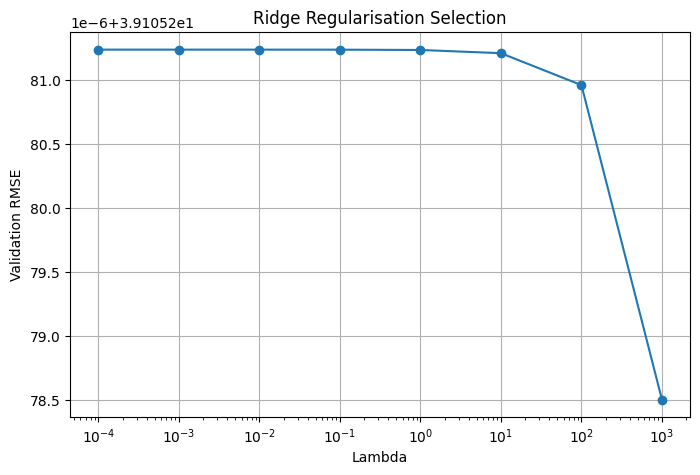

In [35]:
# 7. RIDGE REGRESSION WITH VALIDATION-BASED LAMBDA SELECTION
lambdas = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000]
ridge_validation = []
P = np.eye(Xtr.shape[1]); P[0,0] = 0  # do not penalise intercept
for lam in lambdas:
    w = np.linalg.pinv(Xtr.T@Xtr + lam*P) @ Xtr.T@ytr
    ridge_validation.append((lam, regression_metrics(yva, Xva@w)["RMSE"], w))
best_lam, best_val_rmse, w_ridge = min(ridge_validation, key=lambda z:z[1])
ridge_pred = Xte@w_ridge
ridge_results = regression_metrics(yte, ridge_pred)
print("Validation RMSE by lambda:")
for lam, score, _ in ridge_validation: print(f"lambda={lam:>7}: RMSE={score:.4f}")
print("Selected lambda:", best_lam)
print_metrics("RIDGE REGRESSION – TEST RESULTS", ridge_results)
plt.figure(figsize=(8,5)); plt.plot(lambdas,[x[1] for x in ridge_validation],marker='o')
plt.xscale('log'); plt.xlabel('Lambda'); plt.ylabel('Validation RMSE'); plt.title('Ridge Regularisation Selection'); plt.grid(True); plt.show()

## 7. Bayesian Linear Regression\n
Assume a Gaussian prior \(w\sim N(0,\alpha^{-1}I)\) and Gaussian observation noise \(y|X,w\sim N(Xw,\beta^{-1}I)\). The posterior is Gaussian:

\[S_N=(\alpha I+\beta X^TX)^{-1},\qquad m_N=\beta S_NX^Ty.\]

For a new input \(x\), predictive mean is \(x^Tm_N\) and predictive variance is \(\beta^{-1}+x^TS_Nx\).


BAYESIAN LINEAR REGRESSION – TEST RESULTS
         MAE: 20.94121
        RMSE: 39.01916
          R2: 0.01437
Mean predictive standard deviation: 38.959


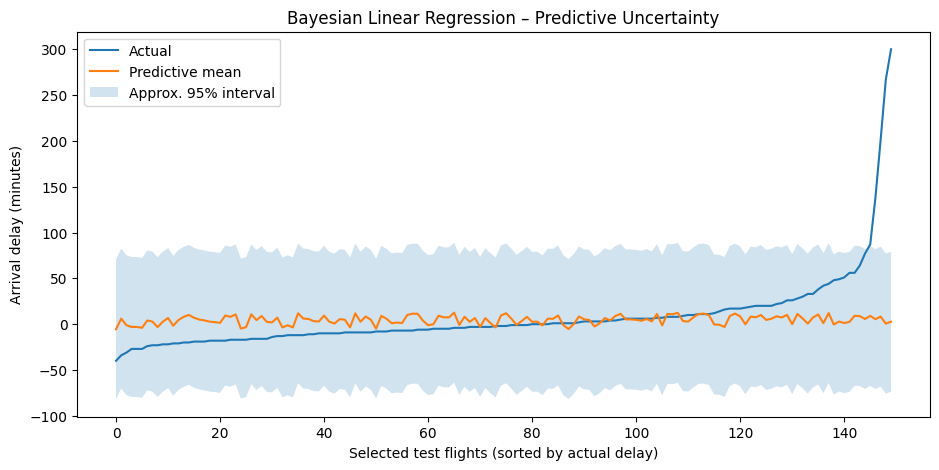

In [36]:
# 8. BAYESIAN LINEAR REGRESSION
alpha_prior = 1.0
noise_variance = max(np.mean((ytr-Xtr@w_mle)**2), 1e-6)
beta = 1.0/noise_variance
I = np.eye(Xtr.shape[1]); I[0,0] = 0  # flat/unregularised intercept prior
S_N = np.linalg.pinv(alpha_prior*I + beta*(Xtr.T@Xtr))
m_N = beta*S_N@Xtr.T@ytr
bayes_mean = Xte@m_N
bayes_var = (1/beta) + np.sum((Xte@S_N)*Xte, axis=1)
bayes_std = np.sqrt(np.maximum(bayes_var,0))
bayes_results = regression_metrics(yte,bayes_mean)
print_metrics("BAYESIAN LINEAR REGRESSION – TEST RESULTS",bayes_results)
print("Mean predictive standard deviation:",round(float(bayes_std.mean()),4))
# Plot a small random sample with 95% predictive intervals
show = np.random.choice(len(yte), min(150,len(yte)), replace=False)
order = np.argsort(yte[show])
plt.figure(figsize=(11,5)); plt.plot(yte[show][order],label='Actual',linewidth=1.5)
plt.plot(bayes_mean[show][order],label='Predictive mean')
plt.fill_between(np.arange(len(show)), (bayes_mean[show]-1.96*bayes_std[show])[order],
                 (bayes_mean[show]+1.96*bayes_std[show])[order],alpha=.2,label='Approx. 95% interval')
plt.title('Bayesian Linear Regression – Predictive Uncertainty'); plt.xlabel('Selected test flights (sorted by actual delay)'); plt.ylabel('Arrival delay (minutes)'); plt.legend(); plt.show()

## 8. Linear Classification – Discriminant Function\n
A linear discriminant function has the form \(g(x)=w^Tx+w_0\). The predicted class is 1 when \(g(x)\geq 0\), otherwise class 0. Here, the weights are learned by minimising logistic cross-entropy with gradient descent; the decision boundary remains linear.

In [38]:
# 9. LOGISTIC REGRESSION – DISCRIMINATIVE LINEAR CLASSIFIER
# Gradient descent implementation from scratch
def fit_logistic(X, y, learning_rate=0.08,
                 epochs=1000, l2=0.01):

    w = np.zeros(X.shape[1])

    n0 = np.sum(y == 0)
    n1 = np.sum(y == 1)

    weights = np.where(y == 1,
                       len(y)/(2*n1),
                       len(y)/(2*n0))

    for epoch in range(epochs):
        p = sigmoid(X @ w)

        grad = X.T @ (weights*(p-y)) / len(y)
        grad += l2*np.r_[0, w[1:]] / len(y)

        w -= learning_rate*grad

    return w

## 9. Probabilistic Generative Model – Gaussian Class-Conditional Model\n
The generative approach models \(p(x|C_k)\) and the prior \(p(C_k)\), then applies Bayes rule:

\[p(C_k|x)=\frac{p(x|C_k)p(C_k)}{\sum_jp(x|C_j)p(C_j)}.\]

This implementation uses a Gaussian distribution with a diagonal covariance matrix for each class (conditional feature independence assumption).

In [39]:
# 10. GAUSSIAN GENERATIVE CLASSIFIER (DIAGONAL COVARIANCE)
class GaussianGenerative:
    def fit(self,X,y):
        self.classes=np.unique(y); self.means=[]; self.vars=[]; self.priors=[]
        for c in self.classes:
            Xc=X[y==c]
            self.means.append(Xc.mean(axis=0))
            self.vars.append(Xc.var(axis=0)+1e-5)
            self.priors.append(len(Xc)/len(X))
        self.means=np.array(self.means); self.vars=np.array(self.vars); self.priors=np.array(self.priors)
    def predict_proba(self,X):
        logp=[]
        for k in range(len(self.classes)):
            v=self.vars[k]; m=self.means[k]
            lp=-0.5*np.sum(np.log(2*np.pi*v)+(X-m)**2/v,axis=1)+np.log(self.priors[k])
            logp.append(lp)
        logp=np.column_stack(logp)
        logp-=logp.max(axis=1,keepdims=True)
        probs=np.exp(logp); return probs/probs.sum(axis=1,keepdims=True)

gen=GaussianGenerative(); gen.fit(X_train,ctr)
gen_prob=gen.predict_proba(X_test)[:,1]
gen_results=classification_metrics(cte,gen_prob)
print_metrics("GAUSSIAN GENERATIVE CLASSIFIER – TEST RESULTS",gen_results)


GAUSSIAN GENERATIVE CLASSIFIER – TEST RESULTS
    Accuracy: 0.82096
   Precision: 0.20307
      Recall: 0.00078
          F1: 0.00155
          TP: 119
          TN: 703524
          FP: 467
          FN: 152992


## 10. Probabilistic Discriminative Model – Logistic Regression\n
Logistic regression directly models \(p(C=1|x)=\sigma(w^Tx)\), rather than modelling the distribution of the input features. The previous logistic model is the discriminative model. We compare it with the Gaussian generative model below.

                  Model  Accuracy  Precision   Recall       F1  TP     TN  FP     FN
    Gaussian generative  0.820956   0.203072 0.000777 0.001549 119 703524 467 152992
Logistic discriminative  0.821362   0.000000 0.000000 0.000000   0 703991   0 153111


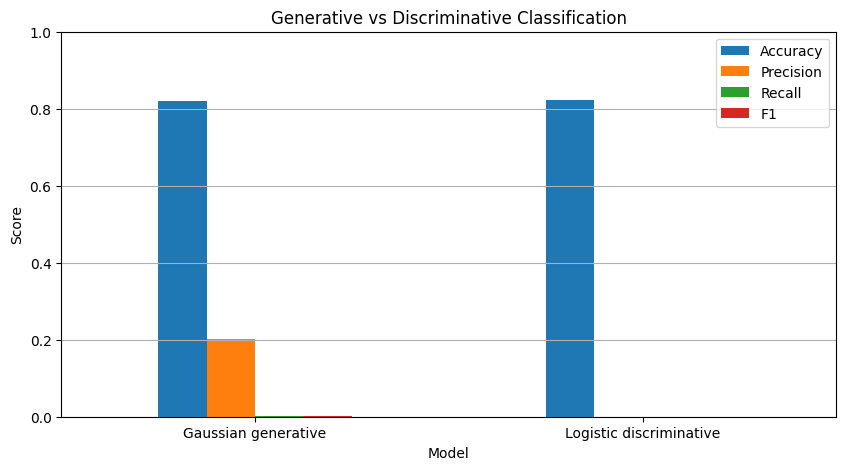

In [40]:
# 11. GENERATIVE VS DISCRIMINATIVE COMPARISON
classification_comparison=pd.DataFrame([
    {"Model":"Gaussian generative",**gen_results},
    {"Model":"Logistic discriminative",**log_results}
])
print(classification_comparison.to_string(index=False))
metrics_to_plot=["Accuracy","Precision","Recall","F1"]
classification_comparison.set_index('Model')[metrics_to_plot].plot(kind='bar',figsize=(10,5),ylim=(0,1))
plt.title('Generative vs Discriminative Classification'); plt.ylabel('Score'); plt.xticks(rotation=0); plt.grid(axis='y'); plt.show()

## 11. Bayesian Logistic Regression – Laplace Approximation\n
A Gaussian prior is placed on the logistic-regression weights. The posterior is not Gaussian, so the Laplace approximation uses a Gaussian centred at the maximum a posteriori (MAP) estimate:

\[S=(X^TRX+\lambda I)^{-1},\]
where \(R_{ii}=p_i(1-p_i)\). The diagonal of \(S\) approximates uncertainty in the weights. This notebook uses a Newton/IRLS MAP fit followed by the Laplace covariance approximation.

In [58]:
# 12. MAP LOGISTIC REGRESSION + LAPLACE POSTERIOR APPROXIMATION
def fit_logistic_newton(X,y,lam=1.0,iterations=35):
    w=np.zeros(X.shape[1]); penalty=np.eye(X.shape[1]); penalty[0,0]=0
    for _ in range(iterations):
        p=sigmoid(X@w)
        r=np.maximum(p*(1-p),1e-7)
        n0 = np.sum(y == 0)
        n1 = np.sum(y == 1)

class_weights = np.where(y == 1,len(y)/(2*n1),len(y)/(2*n0))

grad = X.T @ (class_weights*(p-y)) + lam*(penalty@w)

H = (X.T*(r*class_weights)) @ X + lam*penalty
step=np.linalg.pinv(H)@grad
w_new=w-step
if np.linalg.norm(w_new-w)<1e-6:
    w=w_new; break
    w=w_new
p=sigmoid(X@w); r=np.maximum(p*(1-p),1e-7)
H=(X.T*r)@X+lam*penalty
covariance=np.linalg.pinv(H)
return w,covariance

w_map, cov_laplace=fit_logistic_newton(Xtr,ctr,lam=1.0)
laplace_prob=sigmoid(Xte@w_map)
laplace_results=classification_metrics(cte,laplace_prob)
print_metrics("BAYESIAN LOGISTIC (LAPLACE) – MAP CLASSIFICATION",laplace_results)
print("Approximate posterior standard deviations of coefficients:")
print(pd.DataFrame({"Parameter":["Intercept"]+feature_names,
                    "Posterior_SD":np.sqrt(np.maximum(np.diag(cov_laplace),0))}).to_string(index=False))

NameError: name 'y' is not defined

## 12. Kernel Functions and the Kernel Trick\n
A kernel computes an inner product in a transformed feature space without explicitly constructing that space. We demonstrate linear, polynomial and RBF kernels. The SVM below uses the RBF kernel.

Linear kernel shape: (5, 5)
Polynomial kernel shape: (5, 5)
RBF kernel shape: (5, 5)


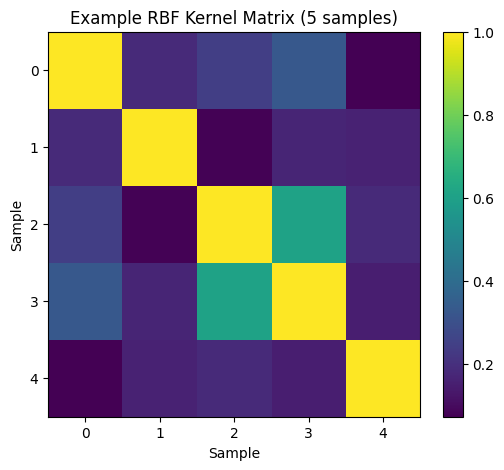

In [43]:
# 13. KERNEL FUNCTIONS – NUMPY IMPLEMENTATION
def linear_kernel(A,B):
    return A@B.T

def polynomial_kernel(A,B,degree=2,c=1.0):
    return (A@B.T+c)**degree

def rbf_kernel(A,B,gamma=None):
    if gamma is None: gamma=1.0/A.shape[1]
    A2=np.sum(A*A,axis=1)[:,None]
    B2=np.sum(B*B,axis=1)[None,:]
    d2=np.maximum(A2+B2-2*(A@B.T),0)
    return np.exp(-gamma*d2)

sample_A=X_train[:5]
print("Linear kernel shape:",linear_kernel(sample_A,sample_A).shape)
print("Polynomial kernel shape:",polynomial_kernel(sample_A,sample_A).shape)
print("RBF kernel shape:",rbf_kernel(sample_A,sample_A).shape)
plt.figure(figsize=(6,5)); plt.imshow(rbf_kernel(sample_A,sample_A),aspect='auto'); plt.colorbar(); plt.title('Example RBF Kernel Matrix (5 samples)'); plt.xlabel('Sample'); plt.ylabel('Sample'); plt.show()

## 13. Support Vector Machine – RBF Kernel (Simplified SMO)\n
The soft-margin SVM solves a dual optimisation problem. The kernel trick replaces dot products with \(K(x_i,x_j)\). To keep the quadratic kernel matrix manageable in Kaggle, the SVM is trained on a stratified subset of the training data. The implementation below is a simplified SMO solver; it is intended for educational demonstration and may not match the convergence or speed of production SVM packages.

In [ ]:
# 14. PREPARE A SMALL, STRATIFIED TRAINING SUBSET FOR KERNEL SVM
rng=np.random.default_rng(42)
svm_limit=1800
idx0=np.where(ctr==0)[0]; idx1=np.where(ctr==1)[0]
n0=min(len(idx0),svm_limit//2); n1=min(len(idx1),svm_limit-n0)
svm_idx=np.r_[rng.choice(idx0,n0,replace=False),rng.choice(idx1,n1,replace=False)]
rng.shuffle(svm_idx)
X_svm=X_train[svm_idx]
y_svm=np.where(ctr[svm_idx]==1,1.0,-1.0)
# validation/test subsets for affordable kernel evaluation
svm_val_n=min(2500,len(X_val)); svm_test_n=min(4000,len(X_test))
X_svm_val=X_val[:svm_val_n]; y_svm_val=cva[:svm_val_n]
X_svm_test=X_test[:svm_test_n]; y_svm_test=cte[:svm_test_n]
print("SVM training rows:",len(X_svm),"validation rows:",len(X_svm_val),"test rows:",len(X_svm_test))

In [44]:
# 15. SIMPLIFIED SEQUENTIAL MINIMAL OPTIMISATION (SMO)
def train_kernel_svm(X,y,C=1.0,gamma=None,max_passes=5,max_iter=12000,tol=1e-3):
    n=len(y); K=rbf_kernel(X,X,gamma)
    alpha=np.zeros(n); b=0.0; passes=0; it=0
    errors=-(y.copy())  # f(x_i)-y_i initially, as alpha and b are zero
    while passes<max_passes and it<max_iter:
        num_changed=0
        for i in range(n):
            Ei=(np.sum(alpha*y*K[:,i])+b)-y[i]
            if ((y[i]*Ei < -tol and alpha[i] < C-1e-8) or
                (y[i]*Ei > tol and alpha[i] > 1e-8)):
                # Select j with largest error difference; fallback random if needed
                f_all=(alpha*y)@K+b
                E_all=f_all-y
                candidates=np.arange(n); candidates=candidates[candidates!=i]
                j=candidates[np.argmax(np.abs(Ei-E_all[candidates]))]
                Ej=E_all[j]
                ai,aj=alpha[i],alpha[j]
                if y[i]!=y[j]:
                    L=max(0,aj-ai); H=min(C,C+aj-ai)
                else:
                    L=max(0,ai+aj-C); H=min(C,ai+aj)
                if H-L<1e-10: continue
                eta=2*K[i,j]-K[i,i]-K[j,j]
                if eta>=-1e-12: continue
                alpha[j]=aj-y[j]*(Ei-Ej)/eta
                alpha[j]=np.clip(alpha[j],L,H)
                if abs(alpha[j]-aj)<1e-6:
                    alpha[j]=aj; continue
                alpha[i]=ai+y[i]*y[j]*(aj-alpha[j])
                b1=b-Ei-y[i]*(alpha[i]-ai)*K[i,i]-y[j]*(alpha[j]-aj)*K[i,j]
                b2=b-Ej-y[i]*(alpha[i]-ai)*K[i,j]-y[j]*(alpha[j]-aj)*K[j,j]
                if 1e-8<alpha[i]<C-1e-8: b=b1
                elif 1e-8<alpha[j]<C-1e-8: b=b2
                else: b=(b1+b2)/2
                num_changed+=1
            it+=1
            if it>=max_iter: break
        passes=passes+1 if num_changed==0 else 0
        if it%2000==0: print("SMO iterations:",it,"changed pairs in pass:",num_changed)
    return {"X":X,"y":y,"alpha":alpha,"b":b,"gamma":gamma,"C":C,"iterations":it}

def svm_decision(model,Xnew,batch_size=500):
    out=[]
    for start in range(0,len(Xnew),batch_size):
        K=rbf_kernel(Xnew[start:start+batch_size],model['X'],model['gamma'])
        out.extend(K@(model['alpha']*model['y'])+model['b'])
    return np.asarray(out)

start=time.time()
svm_model=train_kernel_svm(X_svm,y_svm,C=1.0,gamma=1.0/X_svm.shape[1],max_passes=4,max_iter=9000)
svm_time=time.time()-start
svm_test_decision=svm_decision(svm_model,X_svm_test)
svm_test_prob=sigmoid(svm_test_decision)  # monotonic score mapping for threshold metrics
svm_results=classification_metrics(y_svm_test,svm_test_prob)
print_metrics("RBF KERNEL SVM – TEST SUBSET RESULTS",svm_results)
print("Training time (seconds):",round(svm_time,3))
print("Support vectors:",int(np.sum(svm_model['alpha']>1e-6)))


RBF KERNEL SVM – TEST SUBSET RESULTS
    Accuracy: 0.19750
   Precision: 0.18639
      Recall: 0.99189
          F1: 0.31381
          TP: 734
          TN: 56
          FP: 3204
          FN: 6
Training time (seconds): 11.573
Support vectors: 152


## 14. Unit 2 Model Comparisons

                     Model       MAE      RMSE        R2
       MLE / Least Squares 20.941251 39.019158  0.014366
   Huber Robust Regression 19.063034 39.759448 -0.023389
          Ridge Regression 20.941224 39.019159  0.014366
Bayesian Linear Regression 20.941210 39.019160  0.014365


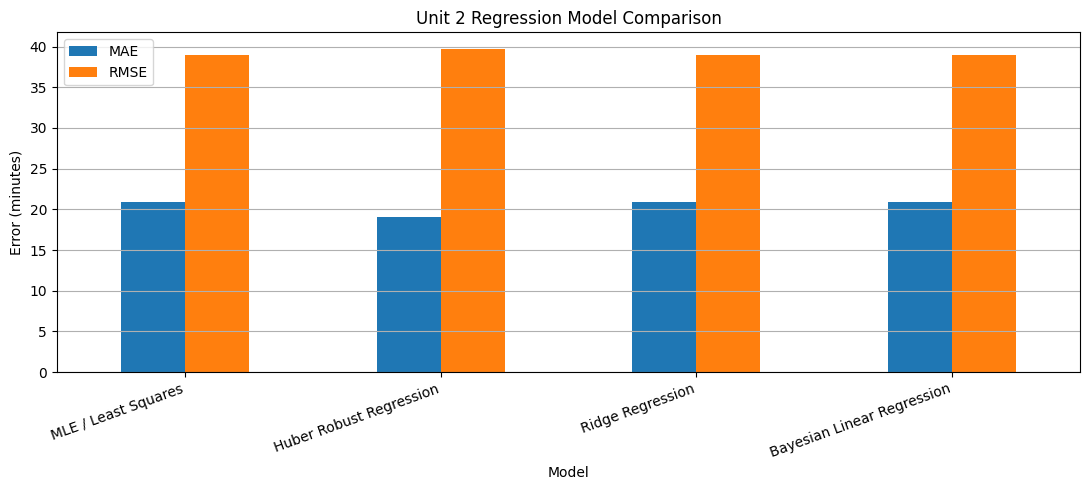

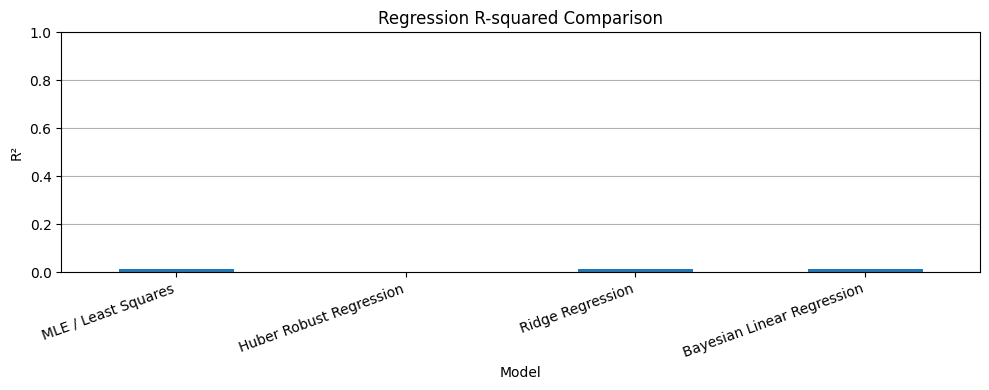

In [45]:
# 16. REGRESSION MODEL COMPARISON
regression_comparison=pd.DataFrame([
    {"Model":"MLE / Least Squares",**mle_results},
    {"Model":"Huber Robust Regression",**huber_results},
    {"Model":"Ridge Regression",**ridge_results},
    {"Model":"Bayesian Linear Regression",**bayes_results}
])
print(regression_comparison.to_string(index=False))
regression_comparison.set_index('Model')[['MAE','RMSE']].plot(kind='bar',figsize=(11,5))
plt.title('Unit 2 Regression Model Comparison'); plt.ylabel('Error (minutes)'); plt.xticks(rotation=20,ha='right'); plt.grid(axis='y'); plt.tight_layout(); plt.show()
regression_comparison.set_index('Model')['R2'].plot(kind='bar',figsize=(10,4),ylim=(0,1))
plt.title('Regression R-squared Comparison'); plt.ylabel('R²'); plt.xticks(rotation=20,ha='right'); plt.grid(axis='y'); plt.tight_layout(); plt.show()

                          Model  Accuracy  Precision   Recall       F1  TP     TN   FP     FN
            Gaussian Generative  0.820956   0.203072 0.000777 0.001549 119 703524  467 152992
        Logistic Discriminative  0.821362   0.000000 0.000000 0.000000   0 703991    0 153111
Bayesian Logistic (Laplace MAP)  0.821362   0.000000 0.000000 0.000000   0 703991    0 153111
   RBF Kernel SVM (test subset)  0.197500   0.186389 0.991892 0.313809 734     56 3204      6


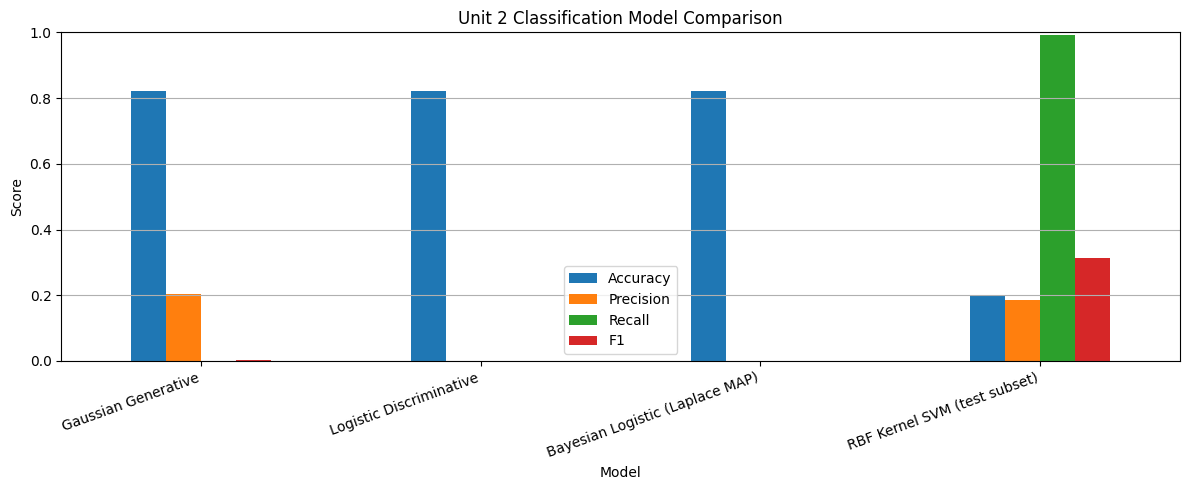

In [46]:
# 17. CLASSIFICATION MODEL COMPARISON
classification_all=pd.DataFrame([
    {"Model":"Gaussian Generative",**gen_results},
    {"Model":"Logistic Discriminative",**log_results},
    {"Model":"Bayesian Logistic (Laplace MAP)",**laplace_results},
    {"Model":"RBF Kernel SVM (test subset)",**svm_results}
])
print(classification_all.to_string(index=False))
classification_all.set_index('Model')[['Accuracy','Precision','Recall','F1']].plot(kind='bar',figsize=(12,5),ylim=(0,1))
plt.title('Unit 2 Classification Model Comparison'); plt.ylabel('Score'); plt.xticks(rotation=20,ha='right'); plt.grid(axis='y'); plt.tight_layout(); plt.show()

## 15. Interpretation and Results\n
Run all cells and use the printed test metrics as your actual results. Do not copy expected or previously obtained Unit 1 scores into this section because the feature set and data split are different.

### What to discuss
- **MLE / least squares:** baseline regression model; sensitive to unusually large residuals.
- **Huber regression:** reduces the influence of large residuals compared with squared-error regression.
- **Ridge regression:** controls coefficient size; validation data selects the regularisation strength.
- **Bayesian linear regression:** provides a predictive mean and uncertainty interval, not only a point prediction.
- **Generative classifier:** estimates class-conditional feature distributions and class priors.
- **Logistic classifier:** directly estimates the probability of a delayed flight.
- **Laplace approximation:** approximates the posterior around the MAP logistic-regression weights with a Gaussian distribution.
- **Kernel SVM:** uses an RBF similarity function to learn a nonlinear decision boundary.

### Limitations
1. `ARRIVAL_DELAY` is the target, and only scheduled-flight information is used as input. Actual departure delay and post-flight delay-cause fields are excluded.
2. Cancellation prediction is not implemented in this Unit 2 notebook because this modelling target is arrival delay, not cancellation.
3. The kernel SVM is trained on a subset because its kernel matrix requires quadratic memory in the number of training samples. Its metrics are calculated on a test subset; compare them with this limitation in mind.
4. The Gaussian generative model uses diagonal covariance as a simplifying assumption.
5. The simplified SMO implementation is educational and may need more iterations or parameter tuning for full convergence.

## 16. Final Result (complete after execution)

**Result:** The Unit 2 regression and classification algorithms were implemented using mathematical formulations and NumPy. The final comparison identifies the strongest model on the held-out test data according to the reported metrics. Insert the actual metric values and explain the observed differences after running the notebook.